# QVGA vs Original Resolution — Comparison

Quantifies how resizing every input frame to **QVGA (320x240)** before processing affects the results, for both the **library** and **native** backends and both the **slow** and **fast** masks.

| group | original-resolution results | QVGA results |
| --- | --- | --- |
| lib slow | `results/` | `results_qvga/` |
| lib fast | `results_fast/` | `results_fast_qvga/` |
| native slow | `results_native/` | `results_native_qvga/` |
| native fast | `results_native_fast/` | `results_native_fast_qvga/` |

It reports (1) the **F-measure** at each resolution and their difference, and (2) the **mask difference** — how much the output masks themselves change when the pipeline runs at QVGA. Masks of different sizes are aligned by nearest-neighbour resizing to the smaller resolution before comparison (the same rule the evaluator uses).

In [1]:
import glob
import os
import re
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.float_format', lambda v: f'{v:.4f}')

VARIANTS = ['basic', '1fps', '0_5fps', '0_1fps']
GROUPS = {
    'lib slow': {'original': 'results', 'qvga': 'results_qvga'},
    'lib fast': {'original': 'results_fast', 'qvga': 'results_fast_qvga'},
    'native slow': {'original': 'results_native', 'qvga': 'results_native_qvga'},
    'native fast': {'original': 'results_native_fast', 'qvga': 'results_native_fast_qvga'},
}
# Frames sampled per sequence for the mask-difference pass (1 = every frame).
SAMPLE_EVERY = 10

## 1. F-measure: original vs QVGA

Loaded from each tree's `eval_summary.csv`.

In [2]:
def load_summary(results_dir):
    """Load an eval_summary.csv, dropping the trailing average row."""
    df = pd.read_csv(Path(results_dir) / 'eval_summary.csv')
    return df[df['case'] != 'average'].set_index('case')[VARIANTS]


def group_table(original_dir, qvga_dir):
    """Sequence x (variant, {orig, qvga, Δ}) F-measure table for a group."""
    original, qvga = load_summary(original_dir), load_summary(qvga_dir)
    columns = {}
    for variant in VARIANTS:
        columns[(variant, 'orig')] = original[variant]
        columns[(variant, 'qvga')] = qvga[variant]
        columns[(variant, 'Δ')] = original[variant] - qvga[variant]
    table = pd.DataFrame(columns)
    table.columns = pd.MultiIndex.from_tuples(table.columns)
    table.loc['average'] = table.mean()
    return table


f_tables = {
    name: group_table(paths['original'], paths['qvga'])
    for name, paths in GROUPS.items()
}

### Summary — mean F-measure and its shift under QVGA

In [3]:
summary = pd.DataFrame(
    {
        name: {
            'meanF original': table.xs('orig', axis=1, level=1).loc['average'].mean(),
            'meanF qvga': table.xs('qvga', axis=1, level=1).loc['average'].mean(),
            'mean |ΔF|': table.xs('Δ', axis=1, level=1).drop('average').abs().values.mean(),
            'max |ΔF|': table.xs('Δ', axis=1, level=1).drop('average').abs().values.max(),
        }
        for name, table in f_tables.items()
    }
).T
summary

,meanF original,meanF qvga,mean |ΔF|,max |ΔF|
lib slow,0.4067,0.4056,0.0011,0.0047
lib fast,0.5554,0.5528,0.0027,0.0136
native slow,0.4067,0.4056,0.0011,0.0047
native fast,0.5554,0.5528,0.0027,0.0136


### Per-group detail (F-measure: original vs QVGA per sequence and variant)

In [4]:
for name, table in f_tables.items():
    print(name)
    display(table)

lib slow


basic                 1fps               0_5fps         \
                     orig   qvga      Δ   orig   qvga      Δ   orig   qvga   
case                                                                         
boats              0.5390 0.5390 0.0000 0.1774 0.1774 0.0000 0.1633 0.1633   
busStation         0.6732 0.6704 0.0028 0.6802 0.6786 0.0016 0.6786 0.6769   
canoe              0.5575 0.5575 0.0000 0.4313 0.4313 0.0000 0.4316 0.4316   
traffic            0.3643 0.3643 0.0000 0.2657 0.2657 0.0000 0.3847 0.3847   
tramCrossroad_1fps 0.1914 0.1867 0.0047 0.1914 0.1867 0.0047 0.1615 0.1573   
turnpike_0_5fps    0.4801 0.4801 0.0000 0.4801 0.4801 0.0000 0.4801 0.4801   
average            0.4676 0.4663 0.0013 0.3710 0.3700 0.0011 0.3833 0.3823   

                          0_1fps                
                        Δ   orig   qvga      Δ  
case                                            
boats              0.0000 0.1341 0.1341 0.0000  
busStation         0.0017 0.6798 0.6772 0.0026  
canoe              0.0000 0.5908 0.5908 0.0000  
traffic            0.0000 0.4786 0.4786 0.0000  
tramCrossroad_1fps 0.0042 0.1289 0.1250 0.0039  
turnpike_0_5fps    0.0000 0.4160 0.4160 0.0000  
average            0.0010 0.4047 0.4036 0.0011

lib fast


basic                 1fps               0_5fps         \
                     orig   qvga      Δ   orig   qvga      Δ   orig   qvga   
case                                                                         
boats              0.2085 0.2085 0.0000 0.4505 0.4505 0.0000 0.4806 0.4806   
busStation         0.3696 0.3643 0.0053 0.6058 0.5993 0.0065 0.6521 0.6461   
canoe              0.3498 0.3498 0.0000 0.5532 0.5532 0.0000 0.5590 0.5590   
traffic            0.4291 0.4291 0.0000 0.4470 0.4470 0.0000 0.5815 0.5815   
tramCrossroad_1fps 0.6972 0.6879 0.0093 0.6972 0.6879 0.0093 0.7366 0.7260   
turnpike_0_5fps    0.6486 0.6486 0.0000 0.6486 0.6486 0.0000 0.6486 0.6486   
average            0.4505 0.4480 0.0024 0.5671 0.5644 0.0026 0.6097 0.6070   

                          0_1fps                
                        Δ   orig   qvga      Δ  
case                                            
boats              0.0000 0.3912 0.3912 0.0000  
busStation         0.0060 0.6648 0.6608 0.0040  
canoe              0.0000 0.6079 0.6079 0.0000  
traffic            0.0000 0.5141 0.5141 0.0000  
tramCrossroad_1fps 0.0106 0.7181 0.7045 0.0136  
turnpike_0_5fps    0.0000 0.6712 0.6712 0.0000  
average            0.0028 0.5945 0.5916 0.0029

native slow


basic                 1fps               0_5fps         \
                     orig   qvga      Δ   orig   qvga      Δ   orig   qvga   
case                                                                         
boats              0.5391 0.5391 0.0000 0.1774 0.1774 0.0000 0.1633 0.1633   
busStation         0.6732 0.6704 0.0028 0.6802 0.6786 0.0016 0.6786 0.6769   
canoe              0.5576 0.5576 0.0000 0.4313 0.4313 0.0000 0.4316 0.4316   
traffic            0.3643 0.3643 0.0000 0.2657 0.2657 0.0000 0.3847 0.3847   
tramCrossroad_1fps 0.1914 0.1867 0.0047 0.1914 0.1867 0.0047 0.1615 0.1573   
turnpike_0_5fps    0.4801 0.4801 0.0000 0.4801 0.4801 0.0000 0.4801 0.4801   
average            0.4676 0.4664 0.0013 0.3710 0.3700 0.0011 0.3833 0.3823   

                          0_1fps                
                        Δ   orig   qvga      Δ  
case                                            
boats              0.0000 0.1341 0.1341 0.0000  
busStation         0.0017 0.6798 0.6772 0.0026  
canoe              0.0000 0.5908 0.5908 0.0000  
traffic            0.0000 0.4786 0.4786 0.0000  
tramCrossroad_1fps 0.0042 0.1289 0.1250 0.0039  
turnpike_0_5fps    0.0000 0.4160 0.4160 0.0000  
average            0.0010 0.4047 0.4036 0.0011

native fast


basic                 1fps               0_5fps         \
                     orig   qvga      Δ   orig   qvga      Δ   orig   qvga   
case                                                                         
boats              0.2085 0.2085 0.0000 0.4505 0.4505 0.0000 0.4806 0.4806   
busStation         0.3696 0.3643 0.0053 0.6058 0.5993 0.0065 0.6521 0.6461   
canoe              0.3498 0.3498 0.0000 0.5532 0.5532 0.0000 0.5590 0.5590   
traffic            0.4291 0.4291 0.0000 0.4470 0.4470 0.0000 0.5815 0.5815   
tramCrossroad_1fps 0.6972 0.6879 0.0093 0.6972 0.6879 0.0093 0.7366 0.7260   
turnpike_0_5fps    0.6486 0.6486 0.0000 0.6486 0.6486 0.0000 0.6486 0.6486   
average            0.4505 0.4480 0.0024 0.5671 0.5644 0.0026 0.6097 0.6070   

                          0_1fps                
                        Δ   orig   qvga      Δ  
case                                            
boats              0.0000 0.3912 0.3912 0.0000  
busStation         0.0060 0.6647 0.6608 0.0039  
canoe              0.0000 0.6079 0.6079 0.0000  
traffic            0.0000 0.5141 0.5141 0.0000  
tramCrossroad_1fps 0.0106 0.7181 0.7045 0.0136  
turnpike_0_5fps    0.0000 0.6712 0.6712 0.0000  
average            0.0028 0.5945 0.5916 0.0029

## 2. Mask difference: original vs QVGA

For each matched frame the original-resolution and QVGA masks are compared pixel-by-pixel (both first resized to the smaller size with nearest-neighbour). The value is the mean fraction of differing pixels, as a percentage — a direct measure of how much resizing changed the output.

In [5]:
def frame_number(path):
    """Extract the frame number from a mask filename."""
    match = re.search(r'(\d+)', os.path.basename(path))
    return int(match.group(1)) if match else -1


def index_masks(directory):
    """Map frame number -> mask path for one sequence folder."""
    return {frame_number(p): p for p in glob.glob(os.path.join(directory, '*.png'))}


def align(mask_a, mask_b):
    """Resize both boolean masks to the smaller size (nearest-neighbour)."""
    if mask_a.shape == mask_b.shape:
        return mask_a, mask_b
    height, width = mask_a.shape if mask_a.size <= mask_b.size else mask_b.shape
    fit = lambda m: cv2.resize(
        m.astype(np.uint8), (width, height), interpolation=cv2.INTER_NEAREST
    ) > 0
    return fit(mask_a), fit(mask_b)


def sequence_mask_diff(dir_a, dir_b, sample_every):
    """Mean %% of pixels differing between matched masks of two folders."""
    a, b = index_masks(dir_a), index_masks(dir_b)
    common = sorted(set(a) & set(b))[::sample_every]
    if not common:
        return np.nan
    per_frame = []
    for number in common:
        mask_a = cv2.imread(a[number], cv2.IMREAD_GRAYSCALE) > 0
        mask_b = cv2.imread(b[number], cv2.IMREAD_GRAYSCALE) > 0
        mask_a, mask_b = align(mask_a, mask_b)
        per_frame.append(float((mask_a != mask_b).mean()))
    return float(np.mean(per_frame)) * 100.0


def mask_diff_table(original_root, qvga_root, sample_every):
    """Sequence x variant table of original-vs-QVGA mask differences (%%)."""
    sequences = sorted(
        p.name for p in (Path(original_root) / 'basic').iterdir() if p.is_dir()
    )
    data = {
        variant: {
            seq: sequence_mask_diff(
                str(Path(original_root) / variant / seq),
                str(Path(qvga_root) / variant / seq),
                sample_every,
            )
            for seq in sequences
        }
        for variant in VARIANTS
    }
    table = pd.DataFrame(data)[VARIANTS]
    table.loc['average'] = table.mean()
    return table


diff_tables = {
    name: mask_diff_table(paths['original'], paths['qvga'], SAMPLE_EVERY)
    for name, paths in GROUPS.items()
}

### Mask difference per group (% pixels differing, original vs QVGA)

In [6]:
for name, table in diff_tables.items():
    print(name)
    display(table)

lib slow


,basic,1fps,0_5fps,0_1fps
boats,0.0000,0.0000,0.0000,0.0000
busStation,0.4162,0.4154,0.4926,0.0000
canoe,0.0000,0.0000,0.0000,0.0000
traffic,0.0000,0.0000,0.0000,0.0000
tramCrossroad_1fps,1.8741,1.8741,2.1374,2.1400
turnpike_0_5fps,0.0000,0.0000,0.0000,0.0000
average,0.3817,0.3816,0.4383,0.3567


lib fast


,basic,1fps,0_5fps,0_1fps
boats,0.0000,0.0000,0.0000,0.0000
busStation,0.2386,0.3396,0.3880,0.0000
canoe,0.0000,0.0000,0.0000,0.0000
traffic,0.0000,0.0000,0.0000,0.0000
tramCrossroad_1fps,0.5131,0.5131,0.5491,0.6551
turnpike_0_5fps,0.0000,0.0000,0.0000,0.0000
average,0.1253,0.1421,0.1562,0.1092


native slow


,basic,1fps,0_5fps,0_1fps
boats,0.0000,0.0000,0.0000,0.0000
busStation,0.4162,0.4154,0.4926,0.0000
canoe,0.0000,0.0000,0.0000,0.0000
traffic,0.0000,0.0000,0.0000,0.0000
tramCrossroad_1fps,1.8740,1.8740,2.1375,2.1400
turnpike_0_5fps,0.0000,0.0000,0.0000,0.0000
average,0.3817,0.3816,0.4384,0.3567


native fast


,basic,1fps,0_5fps,0_1fps
boats,0.0000,0.0000,0.0000,0.0000
busStation,0.2386,0.3396,0.3880,0.0000
canoe,0.0000,0.0000,0.0000,0.0000
traffic,0.0000,0.0000,0.0000,0.0000
tramCrossroad_1fps,0.5131,0.5131,0.5491,0.6551
turnpike_0_5fps,0.0000,0.0000,0.0000,0.0000
average,0.1253,0.1421,0.1562,0.1092


### Headline numbers

In [7]:
for name in GROUPS:
    mean_df = f_tables[name].xs('Δ', axis=1, level=1).drop('average').abs().values.mean()
    mean_mask = diff_tables[name].loc['average'].mean()
    print(f'{name:12s} mean |ΔF| = {mean_df:.4f}   mean mask difference = {mean_mask:.3f} %')

lib slow     mean |ΔF| = 0.0011   mean mask difference = 0.390 %
lib fast     mean |ΔF| = 0.0027   mean mask difference = 0.133 %
native slow  mean |ΔF| = 0.0011   mean mask difference = 0.390 %
native fast  mean |ΔF| = 0.0027   mean mask difference = 0.133 %


## 3. Graphs

### Mean F-measure: original vs QVGA, per group

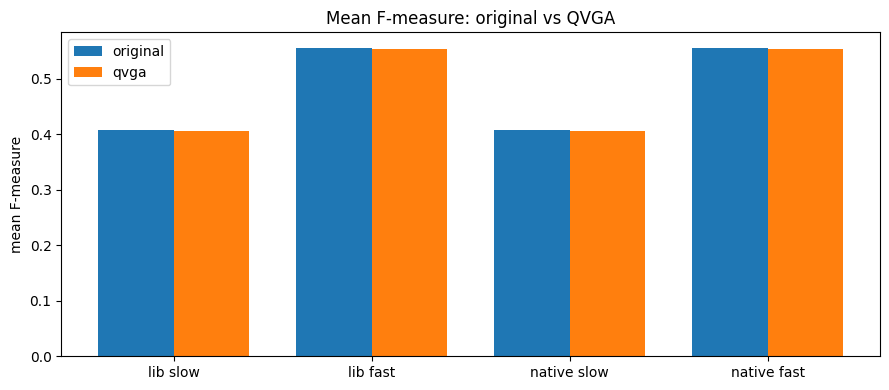

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
names = list(GROUPS)
orig = [summary.loc[n, 'meanF original'] for n in names]
qvga = [summary.loc[n, 'meanF qvga'] for n in names]
x = np.arange(len(names))
width = 0.38
ax.bar(x - width / 2, orig, width, label='original')
ax.bar(x + width / 2, qvga, width, label='qvga')
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel('mean F-measure')
ax.set_title('Mean F-measure: original vs QVGA')
ax.legend()
plt.tight_layout()
plt.show()

### Mask difference (%) per group and variant

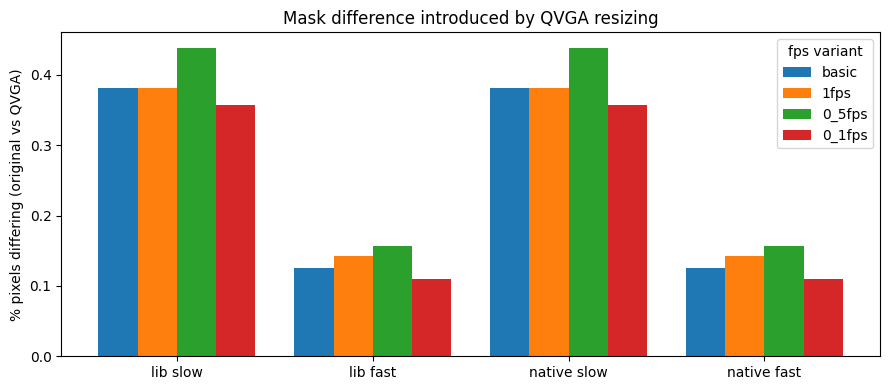

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
names = list(GROUPS)
x = np.arange(len(names))
width = 0.2
for offset, variant in zip(np.linspace(-1.5, 1.5, len(VARIANTS)), VARIANTS):
    values = [diff_tables[n].loc['average', variant] for n in names]
    ax.bar(x + offset * width, values, width, label=variant)
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel('% pixels differing (original vs QVGA)')
ax.set_title('Mask difference introduced by QVGA resizing')
ax.legend(title='fps variant')
plt.tight_layout()
plt.show()

## 4. Notes

* Most CDNET sequences here are already 320x240, so resizing to QVGA is a no-op for them; only sequences at a different native size (e.g. busStation at 360x240) actually change. The per-sequence mask-difference tables make this visible.
* When the backend is `running_average` (the default), lib and native are algorithmically identical, so the `lib` and `native` groups match; any original-vs-QVGA difference is purely the resolution effect.
* `SAMPLE_EVERY` (cell 2) controls the mask-difference sampling; set it to `1` for an exact pass.